# Pothole Detection – Image Segmentation & Masking
Alur: **Load gambar → Preprocessing → Segmentasi (GrabCut) → Masking (morfologi) → Overlay & deteksi → Analisis luas**

Letakkan `lobang1.jpg` dan `lobang2.jpg` satu folder dengan notebook ini (di Colab: upload ke sesi).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

FILES = ['lobang1.jpg', 'lobang2.jpg']
# ROI kasar dalam PECAHAN ukuran gambar (x, y, w, h), bukan piksel absolut.
# Dengan begitu ROI tetap valid berapa pun resolusi/ukuran gambarnya.
ROIS_REL = {'lobang1.jpg': (0.375, 0.53, 0.30, 0.20),
            'lobang2.jpg': (0.19, 0.55, 0.43, 0.30)}

## 1. Load & Preprocessing

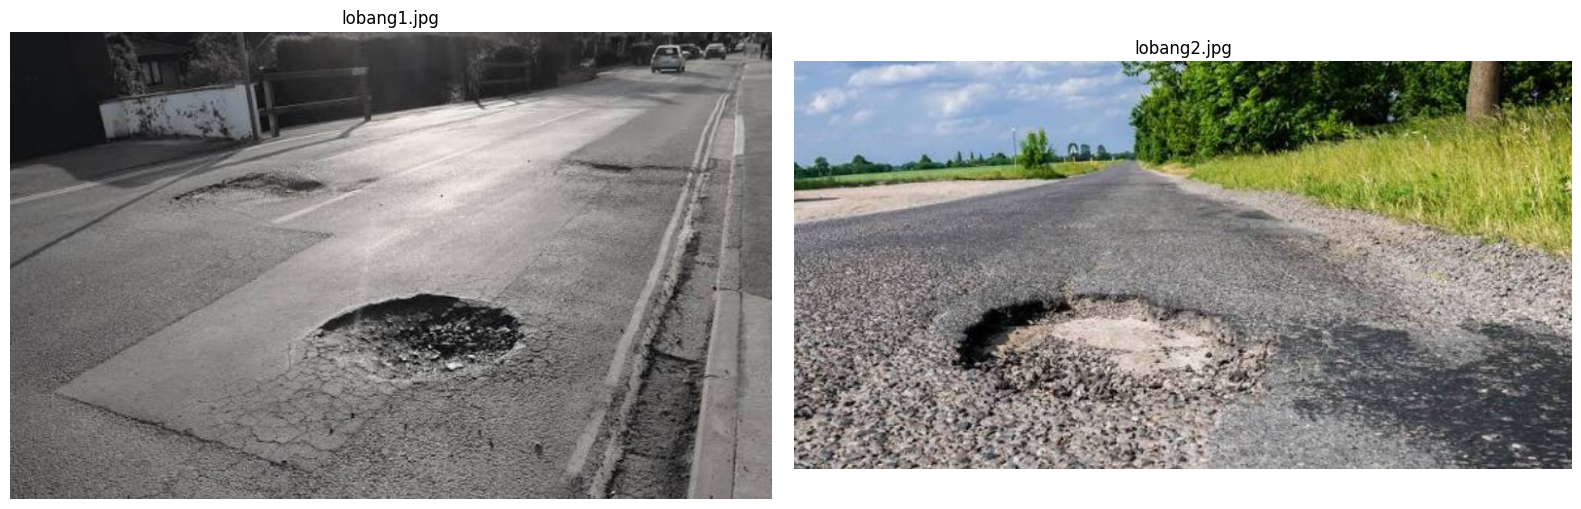

In [2]:
def load(path, width=800):
    img = cv2.imread(path)
    assert img is not None, f'{path} tidak ditemukan'
    return cv2.resize(img, (width, int(img.shape[0] * width / img.shape[1])))

def show(ims, titles, figsize=(16, 5)):
    fig, ax = plt.subplots(1, len(ims), figsize=figsize)
    for a, im, t in zip(np.atleast_1d(ax), ims, titles):
        a.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap='gray' if im.ndim == 2 else None)
        a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

imgs = {f: load(f) for f in FILES}
show(list(imgs.values()), FILES)

## 2. Segmentasi (GrabCut) + 3. Masking
GrabCut memodelkan foreground/background dengan GMM berdasarkan ROI. Hasilnya dibersihkan dengan operasi morfologi (opening → closing) menjadi **mask biner** lubang.

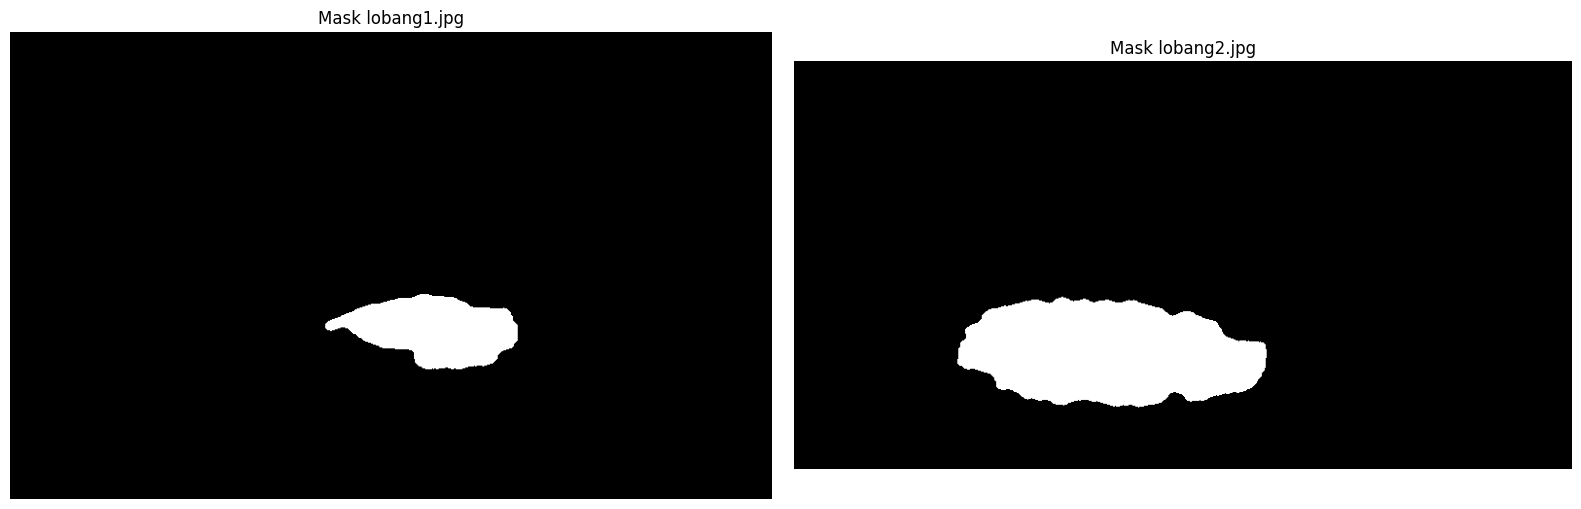

In [3]:
def roi_abs(img, rel):
    """Ubah ROI relatif -> piksel pada gambar saat ini, dan pastikan tidak keluar batas gambar."""
    H, W = img.shape[:2]
    x, y, w, h = rel
    x0, y0 = max(int(x * W), 0), max(int(y * H), 0)
    return (x0, y0, min(int(w * W), W - x0 - 1), min(int(h * H), H - y0 - 1))

def segment_pothole(img, roi, iters=8):
    x, y, w, h = roi
    # Inisialisasi dengan mask: di luar ROI = pasti background,
    # elips dalam ROI = kemungkinan foreground, elips inti = pasti foreground.
    mask = np.full(img.shape[:2], cv2.GC_BGD, np.uint8)
    mask[y:y + h, x:x + w] = cv2.GC_PR_BGD
    c = (x + w // 2, y + h // 2)
    tmp = np.zeros_like(mask); cv2.ellipse(tmp, c, (int(w * .45), int(h * .45)), 0, 0, 360, 1, -1)
    mask[tmp > 0] = cv2.GC_PR_FGD
    tmp[:] = 0; cv2.ellipse(tmp, c, (int(w * .25), int(h * .25)), 0, 0, 360, 1, -1)
    mask[tmp > 0] = cv2.GC_FGD

    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.grabCut(img, mask, None, bgd, fgd, iters, cv2.GC_INIT_WITH_MASK)
    m = np.where((mask == 1) | (mask == 3), 255, 0).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    return m

rois = {f: roi_abs(imgs[f], ROIS_REL[f]) for f in FILES}
masks = {f: segment_pothole(imgs[f], rois[f]) for f in FILES}
show([masks[f] for f in FILES], [f'Mask {f}' for f in FILES])

## 4. Hasil Deteksi (overlay + bounding box)

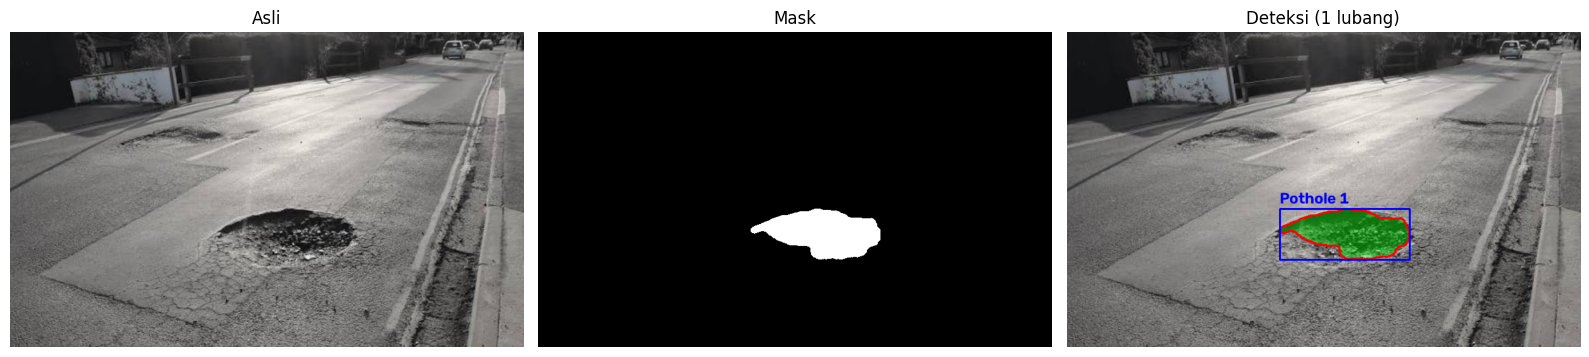

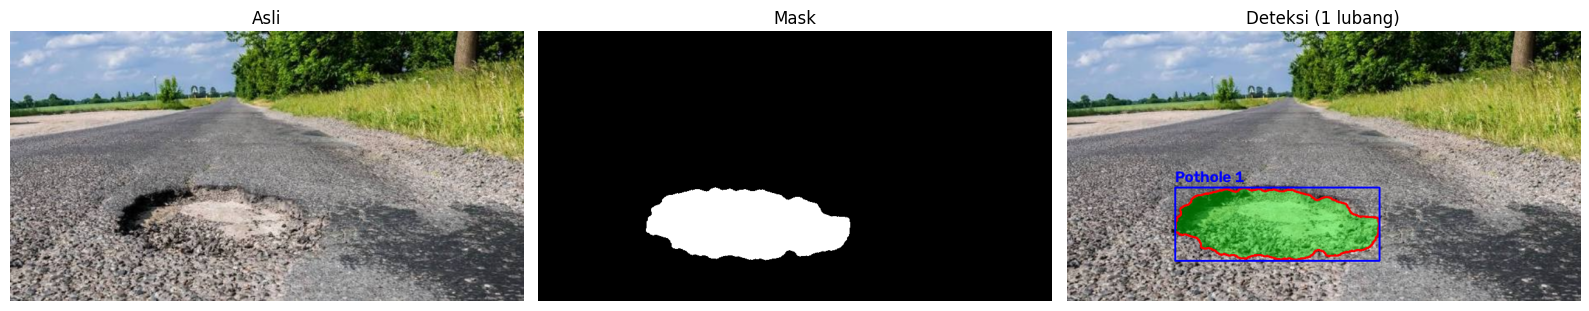

In [4]:
def draw_result(img, mask, label='Pothole'):
    overlay = img.copy(); overlay[mask > 0] = (0, 255, 0)
    out = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = [c for c in cnts if cv2.contourArea(c) > 0.005 * mask.size]
    cv2.drawContours(out, cnts, -1, (0, 0, 255), 2)
    for i, c in enumerate(cnts, 1):
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 2)
        cv2.putText(out, f'{label} {i}', (x, max(y - 8, 18)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    return out, len(cnts)

results = {}
for f in FILES:
    results[f] = draw_result(imgs[f], masks[f])
    show([imgs[f], masks[f], results[f][0]], ['Asli', 'Mask', f'Deteksi ({results[f][1]} lubang)'])

## 5. Ringkasan & Simpan Hasil

In [5]:
import os
os.makedirs('hasil', exist_ok=True)
print(f"{'File':<14}{'Jumlah':>8}{'Luas (px)':>12}{'% area gambar':>16}")
for f in FILES:
    area = int((masks[f] > 0).sum())
    print(f"{f:<14}{results[f][1]:>8}{area:>12}{100 * area / masks[f].size:>15.2f}%")
    name = os.path.splitext(f)[0]
    cv2.imwrite(f'hasil/{name}_mask.png', masks[f])
    cv2.imwrite(f'hasil/{name}_deteksi.png', results[f][0])

File            Jumlah   Luas (px)   % area gambar
lobang1.jpg          1       10194           2.60%
lobang2.jpg          1       26691           7.94%


**Catatan:** GrabCut bersifat semi-otomatis (butuh ROI kasar). Untuk deteksi otomatis penuh tanpa ROI, gunakan model terlatih seperti YOLOv8-seg pada dataset pothole.